In [24]:
from utils.read_write_model import *


def w2c_to_c2w(image):
    R = qvec2rotmat(image.qvec)  # shape (3, 3)
    t = image.tvec  # shape (3, )

    c2w = np.eye(4)
    c2w[:3, :3] = R.T
    c2w[:3, 3] = -R.T @ t
    return c2w


In [5]:
from cumodel import NeuralPrimitiveSceneTileCUDA
from multiprocessing.util import info
import os
import uuid
from tqdm import tqdm
from datetime import datetime
import copy
import time
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import StepLR
from vmodel import NeuralPrimitiveScene
# from vmodel import NeuralPrimitiveScene
from mip360_loader import mip360Dataset
from save_model import save_model
from pruning_densification import *



device = "cuda"
data_dir = "/home/yuzhou/Desktop/datasets/360_v2/bonsai"
dataset = mip360Dataset(data_dir, split="test", factor=4)
initial_num_primitives = 8436
initial_num_primitives = 2183
scene = NeuralPrimitiveSceneTileCUDA(
    num_primitives=initial_num_primitives,
    hidden_dim=32,
    pe_frequencies=6,
    initial_positions=dataset.positions,
).to(device)


model_ckpt_path = "/home/yuzhou/Desktop/output/mip360/8436/scene_epoch_98000.pt"
model_ckpt_path = "/home/yuzhou/Desktop/output/mip360/delta_b/scene_epoch_0.pt"
if os.path.exists(model_ckpt_path):
    ckpt = torch.load(model_ckpt_path, map_location=device)
    scene.load_state_dict(ckpt)
    print(f"[Checkpoint] Loaded model from {model_ckpt_path}")


def _build_projection_from_focal(focal: float, W: int, H: int, near: float = 0.001, far: float = 100.0, device: str | torch.device = "cpu"):
    """Match the viewer's perspective projection convention used by tile_cuda culling."""
    focal = float(focal)
    # vertical fov from focal length (pixels)
    fov_y = 2.0 * float(torch.atan(torch.tensor((0.5 * H) / (focal + 1e-8))))
    aspect = float(W) / float(H)
    t = float(torch.tan(torch.tensor(fov_y / 2.0)))
    r = t * aspect
    P = torch.zeros(4, 4, dtype=torch.float32, device=device)
    P[0, 0] = 1.0 / r
    P[1, 1] = 1.0 / t
    P[2, 2] = -(far + near) / (far - near)
    P[3, 2] = 1.0
    P[2, 3] = -(2 * far * near) / (far - near)
    return P


def _c2w_to_view_matrix(c2w_3x4: torch.Tensor, device: str | torch.device):
    """Convert (3,4) camera-to-world to (4,4) world-to-camera (view) matrix."""
    c2w_h = torch.eye(4, dtype=torch.float32, device=device)
    c2w_h[:3, :4] = c2w_3x4.to(device=device, dtype=torch.float32)
    view = torch.inverse(c2w_h)
    return view


psnr_all = 0

"""
for img_idx in tqdm(range(len(dataset))):
    # ---------------- Load data ----------------
    rays_o_hw, rays_d_hw, img_hw3, pose = dataset[img_idx]
    Himg, Wimg = img_hw3.shape[0], img_hw3.shape[1]
    scene.set_image_size(Wimg, Himg)

    rays_o_batch = rays_o_hw.reshape(-1, 3).to(device, non_blocking=True)
    rays_d_batch = rays_d_hw.reshape(-1, 3).to(device, non_blocking=True)
    rgbs_batch = img_hw3.reshape(-1, 3).to(device, non_blocking=True)

    view_matrix = _c2w_to_view_matrix(pose, device=device)
    proj_matrix = _build_projection_from_focal(dataset.focal, Wimg, Himg, device=device)


    pred = scene(
        rays_o_batch, rays_d_batch,
        score_threshold=1e-3,
        bg_color=torch.zeros(3, device=device),
        view_matrix=view_matrix,
        proj_matrix=proj_matrix,
    )

    psnr = -10 * torch.log10(torch.mean((pred - rgbs_batch) ** 2)).item()
    print(f"Image {img_idx}: PSNR = {psnr:.2f}")
    psnr_all += psnr

    import matplotlib.pyplot as plt
    pred_img = pred.cpu().view(1, 520, 780, 3)
    gt_img = rgbs_batch.cpu().view(1, 520, 780, 3)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ax0_img = axes[0].imshow(gt_img[0].detach().numpy())
    axes[0].set_title("Ground Truth")
    ax1_img = axes[1].imshow(pred_img[0].detach().numpy())
    axes[1].set_title(f"Prediction (PSNR: {psnr:.2f} dB)")
    plt.tight_layout()
    plt.ion()
    plt.show()

psnr_final = psnr_all / len(dataset)

print(f"Final average PSNR over {len(dataset)} images: {psnr_final:.2f}")
"""

Loaded 37 images from /home/yuzhou/Desktop/datasets/360_v2/bonsai/images_4
Sampled 2183 initial positions from point cloud's 206613 points
[Checkpoint] Loaded model from /home/yuzhou/Desktop/output/mip360/delta_b/scene_epoch_0.pt


'\nfor img_idx in tqdm(range(len(dataset))):\n    # ---------------- Load data ----------------\n    rays_o_hw, rays_d_hw, img_hw3, pose = dataset[img_idx]\n    Himg, Wimg = img_hw3.shape[0], img_hw3.shape[1]\n    scene.set_image_size(Wimg, Himg)\n\n    rays_o_batch = rays_o_hw.reshape(-1, 3).to(device, non_blocking=True)\n    rays_d_batch = rays_d_hw.reshape(-1, 3).to(device, non_blocking=True)\n    rgbs_batch = img_hw3.reshape(-1, 3).to(device, non_blocking=True)\n\n    view_matrix = _c2w_to_view_matrix(pose, device=device)\n    proj_matrix = _build_projection_from_focal(dataset.focal, Wimg, Himg, device=device)\n\n\n    pred = scene(\n        rays_o_batch, rays_d_batch,\n        score_threshold=1e-3,\n        bg_color=torch.zeros(3, device=device),\n        view_matrix=view_matrix,\n        proj_matrix=proj_matrix,\n    )\n\n    psnr = -10 * torch.log10(torch.mean((pred - rgbs_batch) ** 2)).item()\n    print(f"Image {img_idx}: PSNR = {psnr:.2f}")\n    psnr_all += psnr\n\n    import 

In [6]:
import time
from tqdm import tqdm

# ---------------- Preload all frames ----------------
preloaded = []

for img_idx in range(len(dataset)):
    rays_o_hw, rays_d_hw, img_hw3, pose = dataset[img_idx]

    Himg, Wimg = img_hw3.shape[0], img_hw3.shape[1]

    rays_o_batch = rays_o_hw.reshape(-1, 3).to(device, non_blocking=True)
    rays_d_batch = rays_d_hw.reshape(-1, 3).to(device, non_blocking=True)
    rgbs_batch  = img_hw3.reshape(-1, 3).to(device, non_blocking=True)

    view_matrix = _c2w_to_view_matrix(pose, device=device)
    proj_matrix = _build_projection_from_focal(
        dataset.focal, Wimg, Himg, device=device
    )

    preloaded.append({
        "W": Wimg,
        "H": Himg,
        "rays_o": rays_o_batch,
        "rays_d": rays_d_batch,
        "rgbs": rgbs_batch,
        "view": view_matrix,
        "proj": proj_matrix,
    })

scene.set_image_size(preloaded[0]["W"], preloaded[0]["H"])



In [ ]:
import time, torch
frame = preloaded[0]
# warmup
for _ in range(10):
    _ = scene(frame["rays_o"], frame["rays_d"],
              score_threshold=1e-3,
              bg_color=torch.zeros(3, device=device),
              view_matrix=frame["view"], proj_matrix=frame["proj"])
zerotensor = torch.zeros(3, device=device)
torch.cuda.synchronize()

a = time.time()
for frame in preloaded:
    pred = scene(frame["rays_o"], frame["rays_d"],
                 score_threshold=1e-3,
                 bg_color=zerotensor,
                 view_matrix=frame["view"], proj_matrix=frame["proj"])
torch.cuda.synchronize()

dt = time.time() - a
print(f"Total inference time for {len(preloaded)} frames: {dt:.5f} s")
print(f"Average FPS: {len(preloaded)/dt:.2f}")


Total inference time for 37 frames: 4.55905 s
Average FPS: 8.12


Labels (5): ['bicycle', 'tree', 'chair', 'cup', 'notebook']
CLIP text dim: 512
Selected class: 0 bicycle
Loaded 37 images from /media/sjkim/HDD_3TB/dataset/360_v2/bonsai/images_4
missing: []
unexpected: []
CLIP feature path: /media/sjkim/HDD_3TB/dataset/360_v2/bonsai/rgb_feature_langseg/DSCF5565_fmap_CxHxW.pt | shape(HWC)= (360, 480, 512)


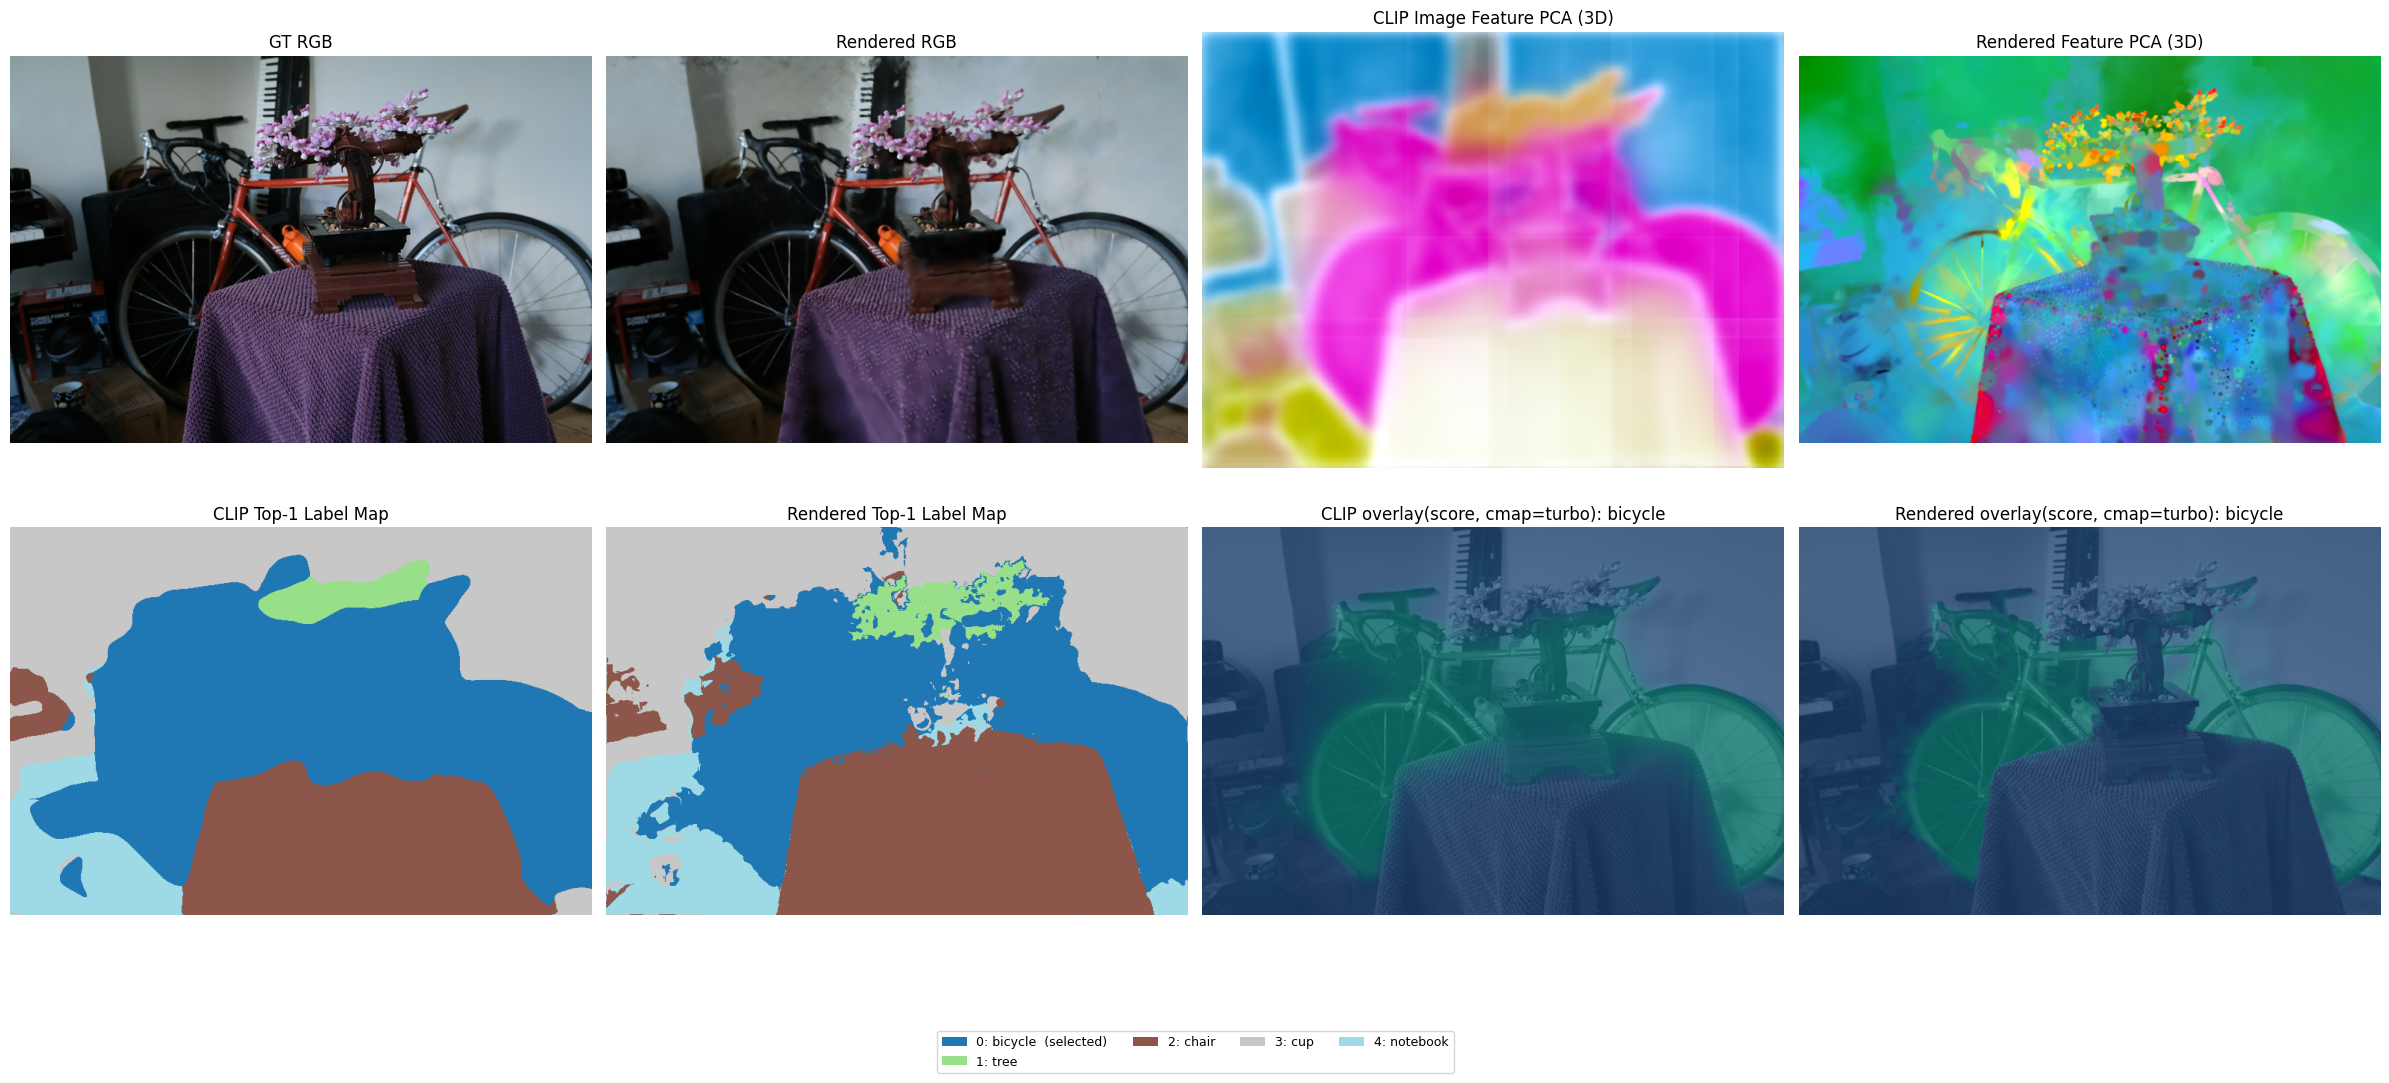

In [4]:
# Render one test viewpoint + selected-class softmax-score overlays (CLIP / Rendered)
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch.nn.functional as F

from cumodel import NeuralPrimitiveSceneTileCUDA
from mip360_loader import mip360Dataset
from feature_decoder import FeatureUpsampleDecoder

try:
    from viewer.text_encoder import CLIPTextEncoder
except Exception:
    from text_encoder import CLIPTextEncoder


def _strip_prefixes(sd):
    out = {}
    for k, v in sd.items():
        nk = k
        if nk.startswith('_orig_mod.'):
            nk = nk[len('_orig_mod.'):]
        if nk.startswith('module.'):
            nk = nk[len('module.'):]
        out[nk] = v
    return out


def _infer_model_dims(sd):
    if 'positions' in sd:
        num_primitives = int(sd['positions'].shape[0])
    elif 'W1' in sd:
        num_primitives = int(sd['W1'].shape[0])
    else:
        raise KeyError('Cannot infer num_primitives from checkpoint')

    if 'W1' not in sd or 'W2' not in sd:
        raise KeyError('Checkpoint is not tile_cuda format (missing W1/W2)')

    hidden_dim = int(sd['W2'].shape[1])
    encoded_dim = int(sd['W1'].shape[2])
    if encoded_dim % 12 != 0:
        raise ValueError('Encoded dim must be divisible by 12, got {}'.format(encoded_dim))
    num_frequencies = encoded_dim // 12

    feature_dim_low = 0
    if 'feat_attr' in sd and torch.is_tensor(sd['feat_attr']) and sd['feat_attr'].ndim == 2:
        feature_dim_low = int(sd['feat_attr'].shape[1])

    return num_primitives, hidden_dim, num_frequencies, feature_dim_low


def _pca3_image(feat_hwc):
    H, W, C = feat_hwc.shape
    x = feat_hwc.reshape(-1, C).float()
    x = x - x.mean(dim=0, keepdim=True)

    if C >= 3:
        q = min(8, C)
        U, S, _V = torch.pca_lowrank(x, q=q, center=False)
        x3 = U[:, :3] * S[:3]
    else:
        pad = torch.zeros(x.shape[0], 3 - C, device=x.device, dtype=x.dtype)
        x3 = torch.cat([x, pad], dim=1)

    lo = x3.quantile(0.01, dim=0, keepdim=True)
    hi = x3.quantile(0.99, dim=0, keepdim=True)
    x3 = (x3 - lo) / (hi - lo + 1e-8)
    x3 = x3.clamp(0.0, 1.0)
    return x3.reshape(H, W, 3).cpu().numpy()


def _build_projection_from_focal(focal, W, H, near=0.001, far=100.0, device='cpu'):
    focal = float(focal)
    fov_y = 2.0 * float(torch.atan(torch.tensor((0.5 * H) / (focal + 1e-8))))
    aspect = float(W) / float(H)
    t = float(torch.tan(torch.tensor(fov_y / 2.0)))
    r = t * aspect
    P = torch.zeros(4, 4, dtype=torch.float32, device=device)
    P[0, 0] = 1.0 / r
    P[1, 1] = 1.0 / t
    P[2, 2] = -(far + near) / (far - near)
    P[3, 2] = 1.0
    P[2, 3] = -(2 * far * near) / (far - near)
    return P


def _c2w_to_view_matrix(c2w_3x4, device):
    c2w_h = torch.eye(4, dtype=torch.float32, device=device)
    c2w_h[:3, :4] = c2w_3x4.to(device=device, dtype=torch.float32)
    return torch.inverse(c2w_h)


def _resolve_view_stem(dataset_obj, idx):
    if hasattr(dataset_obj, 'image_paths_selected') and isinstance(dataset_obj.image_paths_selected, list) and len(dataset_obj.image_paths_selected) == len(dataset_obj):
        p = dataset_obj.image_paths_selected[idx]
        return os.path.splitext(os.path.basename(p))[0]
    if hasattr(dataset_obj, 'image_paths') and hasattr(dataset_obj, 'select_ids') and len(dataset_obj.select_ids) == len(dataset_obj):
        p = dataset_obj.image_paths[dataset_obj.select_ids[idx]]
        return os.path.splitext(os.path.basename(p))[0]
    raise RuntimeError('Cannot resolve image stem from dataset for feature-file matching.')


def _load_clip_feature_hwc(path):
    loaded = torch.load(path, map_location='cpu')
    if isinstance(loaded, dict):
        if 'feat' in loaded:
            feat = loaded['feat'].float()
        else:
            first_key = next(iter(loaded))
            feat = loaded[first_key].float()
    else:
        feat = loaded.float()

    if feat.ndim != 3:
        raise ValueError('Expected 3D feature tensor at {} but got {}'.format(path, tuple(feat.shape)))

    basename = os.path.basename(path)
    force_chw = ('CxHxW' in basename) or ('CHW' in basename)
    if force_chw:
        feat = feat.permute(1, 2, 0).contiguous()
    elif feat.shape[0] <= 8 and feat.shape[-1] > 8:
        feat = feat.permute(1, 2, 0).contiguous()
    elif feat.shape[-1] <= 8 and feat.shape[0] > 8:
        feat = feat.contiguous()
    elif feat.shape[0] > 8 and feat.shape[-1] > 8:
        feat = feat.contiguous()
    else:
        feat = feat.permute(1, 2, 0).contiguous()
    return feat


def _resize_feat_hwc(feat_hwc, H, W):
    if int(feat_hwc.shape[0]) == int(H) and int(feat_hwc.shape[1]) == int(W):
        return feat_hwc
    x = feat_hwc.permute(2, 0, 1).unsqueeze(0).float()
    x = F.interpolate(x, size=(int(H), int(W)), mode='bilinear', align_corners=False)
    return x.squeeze(0).permute(1, 2, 0).contiguous()


def _load_labels_from_yaml(path):
    labels = []
    try:
        import yaml
        with open(path, 'r') as f:
            data = yaml.safe_load(f)
        if isinstance(data, dict):
            edit = data.get('edit', {})
            if isinstance(edit, dict):
                objs = edit.get('objects', [])
                if isinstance(objs, list):
                    labels = [str(x).strip() for x in objs if str(x).strip()]
    except Exception:
        labels = []

    if len(labels) == 0:
        in_objects = False
        with open(path, 'r') as f:
            for line in f:
                s = line.strip()
                if s.startswith('objects:'):
                    in_objects = True
                    continue
                if in_objects:
                    if s.startswith('- '):
                        lab = s[2:].strip()
                        if lab:
                            labels.append(lab)
                    elif s != '' and (not s.startswith('#')) and (not s.startswith('-')):
                        break

    if len(labels) == 0:
        raise ValueError('No labels found in {}'.format(path))
    return labels


def _decoder_path_from_scene_ckpt(scene_ckpt_path):
    base = os.path.basename(scene_ckpt_path)
    if base.startswith('scene_'):
        dec_base = 'decoder_' + base[len('scene_'):]
    else:
        dec_base = 'decoder_' + base
    return os.path.join(os.path.dirname(scene_ckpt_path), dec_base)


def _decode_rendered_feature_if_needed(render_feat_hwc, target_dim, decoder_ckpt):
    C = int(render_feat_hwc.shape[-1])
    if C == int(target_dim):
        return render_feat_hwc
    if (decoder_ckpt is None) or (str(decoder_ckpt).strip() == ''):
        raise RuntimeError('Rendered feature dim {} != text dim {} and decoder_ckpt is not set.'.format(C, target_dim))
    if not os.path.isfile(decoder_ckpt):
        raise FileNotFoundError('decoder_ckpt not found: {}'.format(decoder_ckpt))

    raw = torch.load(decoder_ckpt, map_location='cpu')
    if isinstance(raw, dict) and 'state_dict' in raw and isinstance(raw['state_dict'], dict):
        raw = raw['state_dict']
    if not isinstance(raw, dict):
        raise TypeError('Decoder checkpoint must be a state_dict dictionary.')
    sd = _strip_prefixes(raw)

    if 'net.0.weight' not in sd or 'net.4.weight' not in sd:
        raise KeyError('Decoder ckpt missing net.0.weight/net.4.weight')

    w1 = sd['net.0.weight']
    w3 = sd['net.4.weight']
    in_dim = int(w1.shape[1])
    hidden = int(w1.shape[0])
    out_dim = int(w3.shape[0])
    if in_dim != C or out_dim != int(target_dim):
        raise ValueError('Decoder dim mismatch: ckpt {}->{} vs required {}->{}'.format(in_dim, out_dim, C, target_dim))

    dec = FeatureUpsampleDecoder(in_dim=in_dim, out_dim=out_dim, hidden_dim=hidden).to(render_feat_hwc.device)
    dec.load_state_dict(sd, strict=True)
    dec.eval()

    with torch.no_grad():
        x = render_feat_hwc.permute(2, 0, 1).unsqueeze(0)
        y = dec(x)
        y = y.squeeze(0).permute(1, 2, 0).contiguous()
    return y


def _softmax_scores(feat_hwc, text_embed, temperature=0.45):
    H, W, D = feat_hwc.shape
    x = feat_hwc.reshape(-1, D).float().to(text_embed.device)
    x = F.normalize(x, dim=1)
    t = F.normalize(text_embed.float(), dim=1)
    sim = torch.matmul(x, t.t())
    prob = torch.softmax(sim / float(temperature), dim=1)
    return prob.reshape(H, W, -1)


def _selected_class_overlay(base_rgb_hwc, score_map_hw, overlay_strength=0.92, gray_gain=0.45, alpha_gamma=0.60, cmap_name='turbo'):
    # base RGB -> grayscale base, then blend fixed colormap(score) by score
    base = torch.from_numpy(base_rgb_hwc).float()
    gray = (0.299 * base[..., 0] + 0.587 * base[..., 1] + 0.114 * base[..., 2]).unsqueeze(-1).repeat(1, 1, 3)
    gray = gray * float(gray_gain)

    score = torch.from_numpy(score_map_hw).float().clamp(0.0, 1.0)
    alpha = (score.pow(float(alpha_gamma)) * float(overlay_strength)).unsqueeze(-1).clamp(0.0, 1.0)

    cmap = plt.get_cmap(cmap_name)
    score_rgb = torch.from_numpy(cmap(score.cpu().numpy())[..., :3]).float()

    overlay = gray * (1.0 - alpha) + score_rgb * alpha
    return overlay.clamp(0.0, 1.0).numpy()


# ==== User config ====
device = 'cuda' if torch.cuda.is_available() else 'cpu'
data_dir = '/media/sjkim/HDD_3TB/dataset/360_v2/bonsai'
ckpt_path = '/home/sjkim/Desktop/featmlp_main.pt'
clip_feature_dir = '/media/sjkim/HDD_3TB/dataset/360_v2/bonsai/rgb_feature_langseg'
label_yaml_path = '/home/sjkim/Documents/mlpsp-semantics/mip360/viewer/configs/vlm_edit_labels.yaml'
clip_model_name = 'ViT-B/32'
clip_download_root = '/tmp/tmp_clip'
view_idx = 0
score_threshold = 1e-3

# score/overlay hyperparams
temperature = 0.45
overlay_strength = 0.92
overlay_cmap = 'turbo'

# Select ONE class to inspect (set one of them)
selected_label = 'bicycle'      # e.g. 'tree'
selected_label_idx = None    # e.g. 1

# Optional: set explicitly if rendered feature dim != CLIP text dim.
decoder_ckpt = '~/Desktop/featmlp_decoder.pt'

os.environ['MLPSP_TILE_ORDER'] = 'tilecenter'

# 1) Load labels and CLIP text embeddings
labels = _load_labels_from_yaml(label_yaml_path)
text_encoder = CLIPTextEncoder(device=torch.device(device), model_name=clip_model_name, download_root=clip_download_root)
text_embed = text_encoder.encode_texts(labels).to(device)
text_dim = int(text_embed.shape[1])
print('Labels ({}): {}'.format(len(labels), labels))
print('CLIP text dim:', text_dim)

# fixed palette per label
cmap = plt.get_cmap('tab20', max(len(labels), 1))
palette_rgb = np.asarray([cmap(i)[:3] for i in range(len(labels))], dtype=np.float32)

# resolve selected class
if selected_label_idx is not None:
    class_idx = int(selected_label_idx)
    if class_idx < 0 or class_idx >= len(labels):
        raise ValueError('selected_label_idx out of range: {}'.format(class_idx))
elif selected_label is not None and str(selected_label).strip() != '':
    key = str(selected_label).strip().lower()
    lut = {str(x).strip().lower(): i for i, x in enumerate(labels)}
    if key not in lut:
        raise ValueError('selected_label not found in yaml labels: {}'.format(selected_label))
    class_idx = int(lut[key])
else:
    class_idx = 0
selected_class_name = labels[class_idx]
print('Selected class:', class_idx, selected_class_name)

# 2) Load test dataset
dataset_test = mip360Dataset(data_dir, split='test', factor=4)

# 3) Load checkpoint and rebuild tile_cuda scene
raw = torch.load(ckpt_path, map_location='cpu')
if isinstance(raw, dict) and 'scene_state_dict' in raw:
    raw = raw['scene_state_dict']
if not isinstance(raw, dict):
    raise TypeError('Checkpoint must be a state_dict dictionary.')

sd = _strip_prefixes(raw)
N, hidden_dim, num_f, feature_dim_low = _infer_model_dims(sd)
scene_eval = NeuralPrimitiveSceneTileCUDA(
    num_primitives=N,
    hidden_dim=hidden_dim,
    pe_frequencies=num_f,
    feature_dim_low=feature_dim_low,
).to(device)
missing, unexpected = scene_eval.load_state_dict(sd, strict=False)
print('missing:', missing)
print('unexpected:', unexpected)
scene_eval.eval()

if feature_dim_low <= 0:
    raise RuntimeError('Checkpoint has no feat_attr (feature branch). Cannot render feature map.')

# 4) Pick one test viewpoint
sample = dataset_test[view_idx]
if len(sample) == 5:
    rays_o_hw, rays_d_hw, gt_rgb_hw3, _feat_gt, pose = sample
else:
    rays_o_hw, rays_d_hw, gt_rgb_hw3, pose = sample

H, W = int(gt_rgb_hw3.shape[0]), int(gt_rgb_hw3.shape[1])
scene_eval.set_image_size(W, H)

rays_o = rays_o_hw.reshape(-1, 3).to(device, non_blocking=True)
rays_d = rays_d_hw.reshape(-1, 3).to(device, non_blocking=True)
view_mat = _c2w_to_view_matrix(pose, device=device)
proj_mat = _build_projection_from_focal(dataset_test.focal, W, H, device=device)

# 5) Render RGB + low-dim feature
with torch.no_grad():
    out = scene_eval(
        rays_o, rays_d,
        score_threshold=score_threshold,
        bg_color=torch.zeros(3, device=device),
        view_matrix=view_mat,
        proj_matrix=proj_mat,
        return_feature=True,
    )

if not (isinstance(out, tuple) and len(out) == 2):
    raise RuntimeError('Expected (rgb, feat_low). Ensure MLPSP_TILE_ORDER=tilecenter and feature model checkpoint.')

render_rgb, render_feat = out
render_rgb_hw3 = render_rgb.reshape(H, W, 3).detach().cpu().numpy()
render_feat_hwc = render_feat.reshape(H, W, feature_dim_low).detach()
render_feat_pca = _pca3_image(render_feat_hwc)
gt_rgb = gt_rgb_hw3.detach().cpu().numpy()

# 6) Load CLIP image embedding feature for same test image and make PCA(3)
stem = _resolve_view_stem(dataset_test, view_idx)
clip_path = os.path.join(clip_feature_dir, stem + '_fmap_CxHxW.pt')
if not os.path.isfile(clip_path):
    candidates = sorted(glob.glob(os.path.join(clip_feature_dir, stem + '*.pt')))
    if len(candidates) == 0:
        raise FileNotFoundError('No CLIP feature file found for stem {} in {}'.format(stem, clip_feature_dir))
    clip_path = candidates[0]

clip_feat_hwc = _load_clip_feature_hwc(clip_path)
clip_feat_pca = _pca3_image(clip_feat_hwc)
print('CLIP feature path:', clip_path, '| shape(HWC)=', tuple(clip_feat_hwc.shape))

# 7) Prepare features for selected-class softmax scoring (dim + size alignment)
clip_feat_for_score = _resize_feat_hwc(clip_feat_hwc, H, W).to(device)

render_feat_for_score = render_feat_hwc.to(device)
if int(render_feat_for_score.shape[-1]) != int(text_dim):
    auto_decoder = _decoder_path_from_scene_ckpt(ckpt_path)
    user_decoder = os.path.expanduser(str(decoder_ckpt).strip()) if str(decoder_ckpt).strip() else ''
    dec_path = user_decoder if user_decoder else (auto_decoder if os.path.isfile(auto_decoder) else '')
    render_feat_for_score = _decode_rendered_feature_if_needed(render_feat_for_score, text_dim, dec_path)

if int(clip_feat_for_score.shape[-1]) != int(text_dim):
    raise RuntimeError('CLIP feature dim {} != CLIP text dim {}'.format(int(clip_feat_for_score.shape[-1]), text_dim))
if int(render_feat_for_score.shape[-1]) != int(text_dim):
    raise RuntimeError('Rendered feature dim {} != CLIP text dim {}'.format(int(render_feat_for_score.shape[-1]), text_dim))

# 8) Cosine -> softmax(label axis)
clip_prob = _softmax_scores(clip_feat_for_score, text_embed, temperature=temperature)
render_prob = _softmax_scores(render_feat_for_score, text_embed, temperature=temperature)

# top-1 class visualization (for row2 col1/2)
clip_top_idx = clip_prob.argmax(dim=-1).detach().cpu().numpy()
render_top_idx = render_prob.argmax(dim=-1).detach().cpu().numpy()
clip_top_map_rgb = palette_rgb[clip_top_idx]
render_top_map_rgb = palette_rgb[render_top_idx]

# selected class score map (for row2 col3/4 overlays)
clip_score_map = clip_prob[..., class_idx].detach().cpu().numpy()
render_score_map = render_prob[..., class_idx].detach().cpu().numpy()

clip_overlay = _selected_class_overlay(
    base_rgb_hwc=np.clip(gt_rgb, 0.0, 1.0),
    score_map_hw=clip_score_map,
    overlay_strength=overlay_strength,
    cmap_name=overlay_cmap,
)
render_overlay = _selected_class_overlay(
    base_rgb_hwc=np.clip(gt_rgb, 0.0, 1.0),
    score_map_hw=render_score_map,
    overlay_strength=overlay_strength,
    cmap_name=overlay_cmap,
)

# 9) Visualize (2x4)
fig, axes = plt.subplots(2, 4, figsize=(24, 11))

axes[0, 0].imshow(np.clip(gt_rgb, 0.0, 1.0))
axes[0, 0].set_title('GT RGB')
axes[0, 0].axis('off')

axes[0, 1].imshow(np.clip(render_rgb_hw3, 0.0, 1.0))
axes[0, 1].set_title('Rendered RGB')
axes[0, 1].axis('off')

axes[0, 2].imshow(np.clip(clip_feat_pca, 0.0, 1.0))
axes[0, 2].set_title('CLIP Image Feature PCA (3D)')
axes[0, 2].axis('off')

axes[0, 3].imshow(np.clip(render_feat_pca, 0.0, 1.0))
axes[0, 3].set_title('Rendered Feature PCA (3D)')
axes[0, 3].axis('off')

axes[1, 0].imshow(np.clip(clip_top_map_rgb, 0.0, 1.0))
axes[1, 0].set_title('CLIP Top-1 Label Map')
axes[1, 0].axis('off')

axes[1, 1].imshow(np.clip(render_top_map_rgb, 0.0, 1.0))
axes[1, 1].set_title('Rendered Top-1 Label Map')
axes[1, 1].axis('off')

axes[1, 2].imshow(np.clip(clip_overlay, 0.0, 1.0))
axes[1, 2].set_title('CLIP overlay(score, cmap={}): {}'.format(overlay_cmap, selected_class_name))
axes[1, 2].axis('off')

axes[1, 3].imshow(np.clip(render_overlay, 0.0, 1.0))
axes[1, 3].set_title('Rendered overlay(score, cmap={}): {}'.format(overlay_cmap, selected_class_name))
axes[1, 3].axis('off')

# Color-label legend (highlight selected class)
legend_handles = []
for i, lab in enumerate(labels):
    title = '{}: {}'.format(i, lab)
    if i == class_idx:
        title = title + '  (selected)'
    legend_handles.append(Patch(facecolor=palette_rgb[i], edgecolor='none', label=title))
fig.legend(handles=legend_handles, loc='lower center', ncol=min(4, max(1, len(labels))), frameon=True, fontsize=9, bbox_to_anchor=(0.5, -0.01))

plt.tight_layout(rect=[0.0, 0.06, 1.0, 1.0])
plt.show()



